In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   Дата          301355 non-null  object
 1   Склад         301355 non-null  int64 
 2   Контрагент    301355 non-null  object
 3   Номенклатура  301355 non-null  object
 4   Количество    301355 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.5+ MB


Сразу переведем столбец "Дата" в правильный формат

In [6]:
df['Дата'] = pd.to_datetime(df['Дата'],format='%Y-%m-%d')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Дата          301355 non-null  datetime64[ns]
 1   Склад         301355 non-null  int64         
 2   Контрагент    301355 non-null  object        
 3   Номенклатура  301355 non-null  object        
 4   Количество    301355 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.5+ MB


Сгруппируйте данные по дате, посчитайте количество продаж

In [20]:
grouped_df = df.groupby('Дата',as_index= False).agg({'Количество':'sum'})

Вывести несколько первых строк сгруппированных данных

In [16]:
grouped_df.head()

,Дата,Количество
0,2018-01-04,3734
1,2018-01-05,3643
2,2018-01-06,3193
3,2018-01-07,3298
4,2018-01-09,4055


Нарисуйте график продаж у `grouped_df`

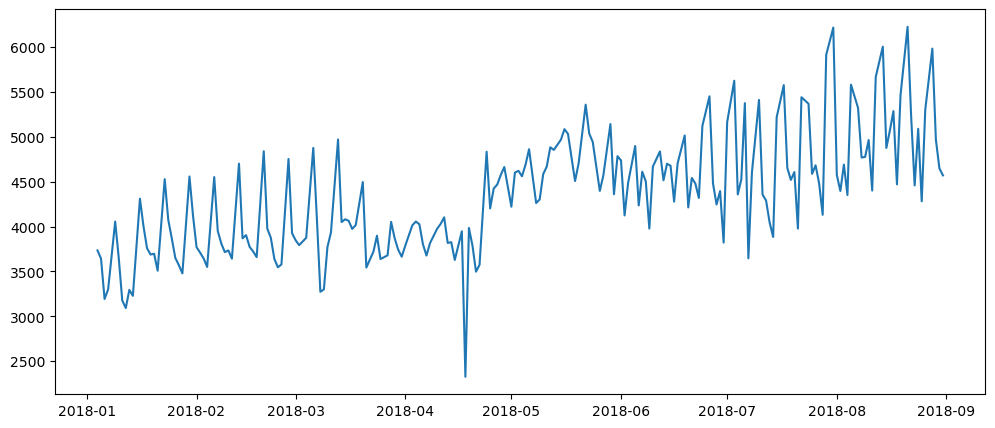

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(grouped_df['Дата'],grouped_df['Количество'])
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

Количество продаж имеет положительный тренд за период с января по сентябрь. Наболюдается резкий спад продаж с конца марта до начала мая. После чего, количество продаж опять повышается.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [29]:
df[df['Количество'] == df['Количество'].max()]

,Дата,Склад,Контрагент,Номенклатура,Количество
218822,2018-06-28,1,address_208,product_0,200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [62]:
df_wednesdays_june = df[(df['Склад'] == 3) & (df['Дата'].dt.dayofweek == 2)&(df['Дата'].dt.month == 6)].groupby('Номенклатура',as_index = False).agg({'Количество':'sum'}).sort_values(by = 'Количество',ascending = False)
df_wednesdays_july = df[(df['Склад'] == 3) & (df['Дата'].dt.dayofweek == 2)&(df['Дата'].dt.month == 7)].groupby('Номенклатура',as_index = False).agg({'Количество':'sum'}).sort_values(by = 'Количество',ascending = False)
df_wednesdays_august = df[(df['Склад'] == 3) & (df['Дата'].dt.dayofweek == 2)&(df['Дата'].dt.month == 8)].groupby('Номенклатура',as_index = False).agg({'Количество':'sum'}).sort_values(by = 'Количество',ascending = False)

print(
    f' Top sales for june = {df_wednesdays_june[df_wednesdays_june['Количество'] == df_wednesdays_june['Количество'].max()]}', '\n\n'
    f' Top sales for july = {df_wednesdays_july[df_wednesdays_july['Количество'] == df_wednesdays_july['Количество'].max()]}','\n\n'
    f' Top sales for august = {df_wednesdays_august[df_wednesdays_august['Количество'] == df_wednesdays_august['Количество'].max()]}'
)

 Top sales for june =   Номенклатура  Количество
1    product_1         616 

 Top sales for july =   Номенклатура  Количество
1    product_1         696 

 Top sales for august =   Номенклатура  Количество
1    product_1         955


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [91]:
temp_df = pd.read_csv('temp.csv', sep=';', skiprows=6, index_col=0)
temp_df.index = pd.to_datetime(temp_df.index, format='%d.%m.%Y %H:%M')
temp_df.index = temp_df.index.date
temp_df = temp_df.reset_index().rename(columns={'index': 'Дата','Местное время в Астане':'T','T':'Местное время в Астане'})
temp_df = temp_df[['Дата', 'T']].sort_values(by='Дата')
temp_df['Дата'] = pd.to_datetime(temp_df['Дата'],format='%Y-%m-%d')
temp_df

,Дата,T
1917,2018-01-04,-13.4
1910,2018-01-04,-20.7
1911,2018-01-04,-17.2
1912,2018-01-04,-14.5
1916,2018-01-04,-12.3
...,...,...
4,2018-08-31,13.2
3,2018-08-31,12.3
2,2018-08-31,11.3
1,2018-08-31,9.6


In [92]:
grouped_df = grouped_df.merge(
    temp_df,
    on = 'Дата',
    how='left'
)
grouped_df

,Дата,Количество,T
0,2018-01-04,3734,-13.4
1,2018-01-04,3734,-20.7
2,2018-01-04,3734,-17.2
3,2018-01-04,3734,-14.5
4,2018-01-04,3734,-12.3
...,...,...,...
1633,2018-08-31,4570,13.2
1634,2018-08-31,4570,12.3
1635,2018-08-31,4570,11.3
1636,2018-08-31,4570,9.6


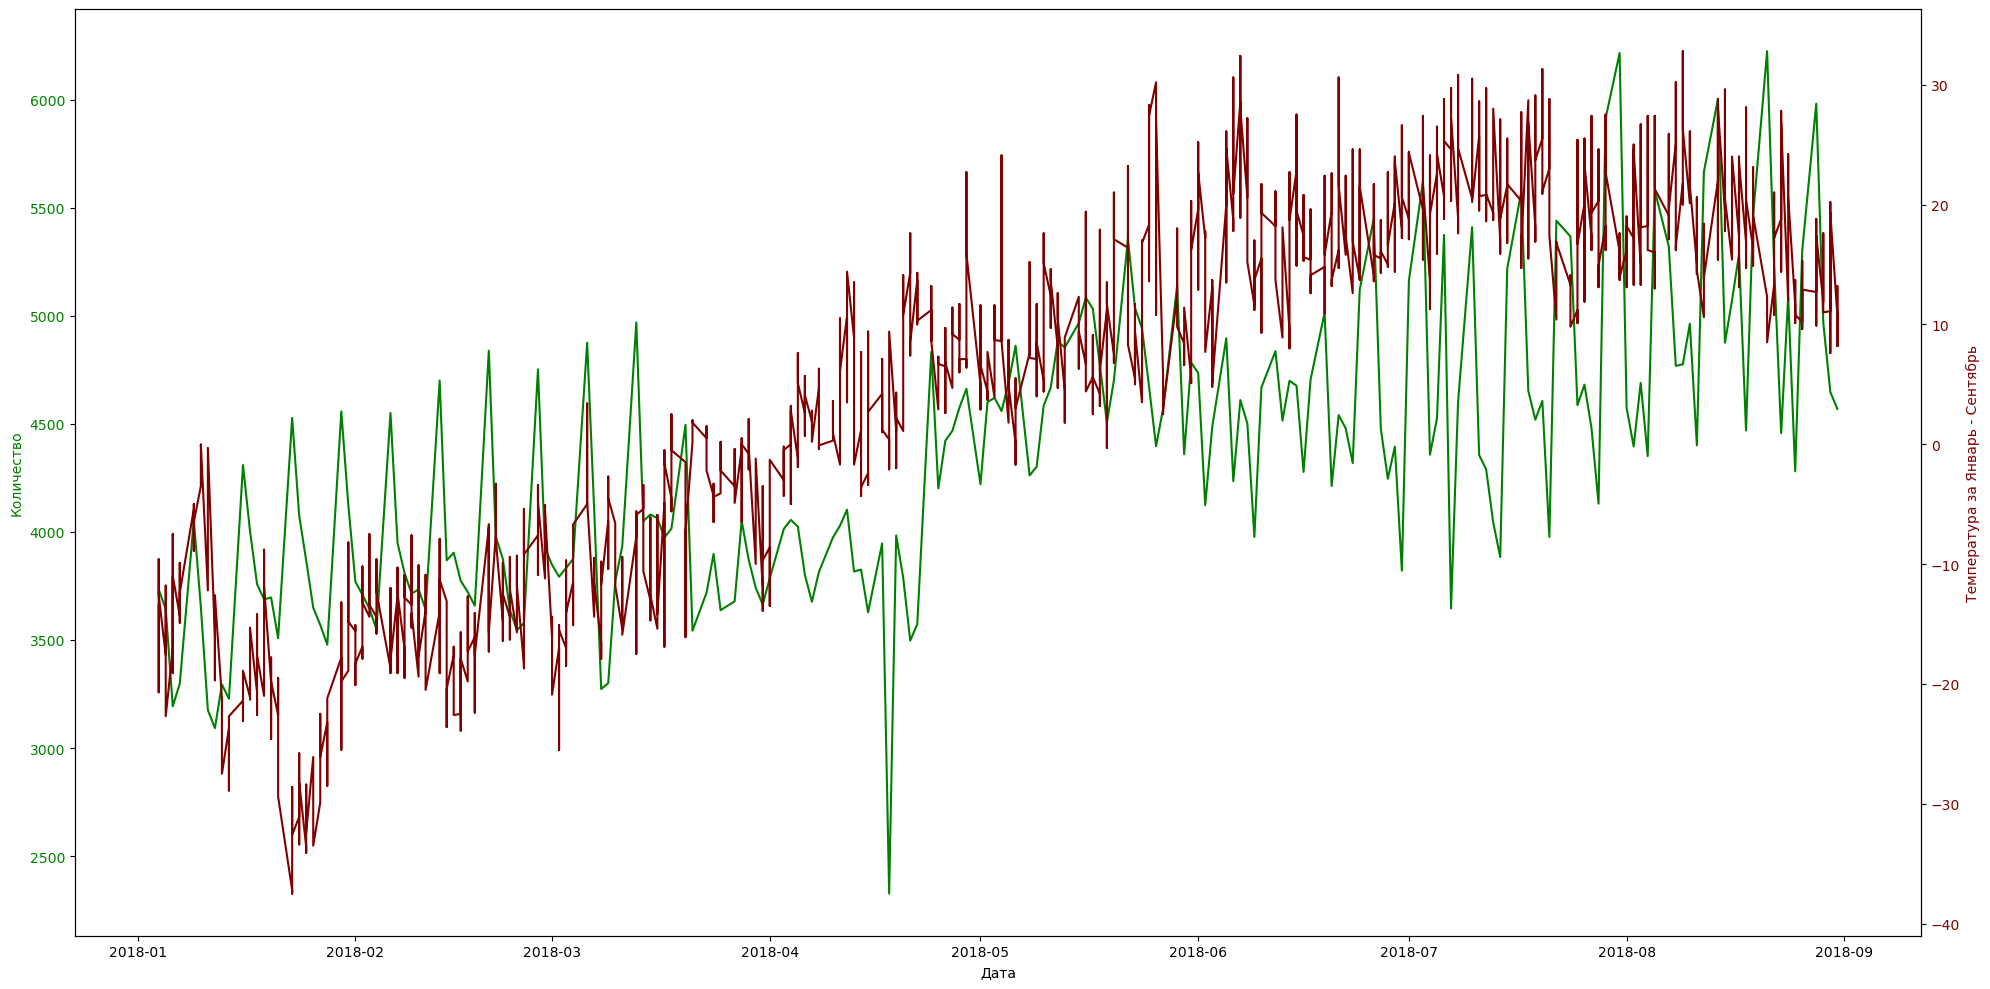

In [108]:
fig, ax1 = plt.subplots(figsize=(20, 10))
ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество',color = 'green')
ax1.plot(grouped_df['Дата'],grouped_df['Количество'], color = 'green')
ax1.tick_params(axis='y', labelcolor = 'green')

ax2 = ax1.twinx()

ax2.set_ylabel('Температура за Январь - Сентябрь',color = 'maroon')
ax2.plot(grouped_df['Дата'],grouped_df['T'], color = 'maroon')
ax2.tick_params(axis='y', labelcolor = 'maroon')
fig.tight_layout()
plt.show()

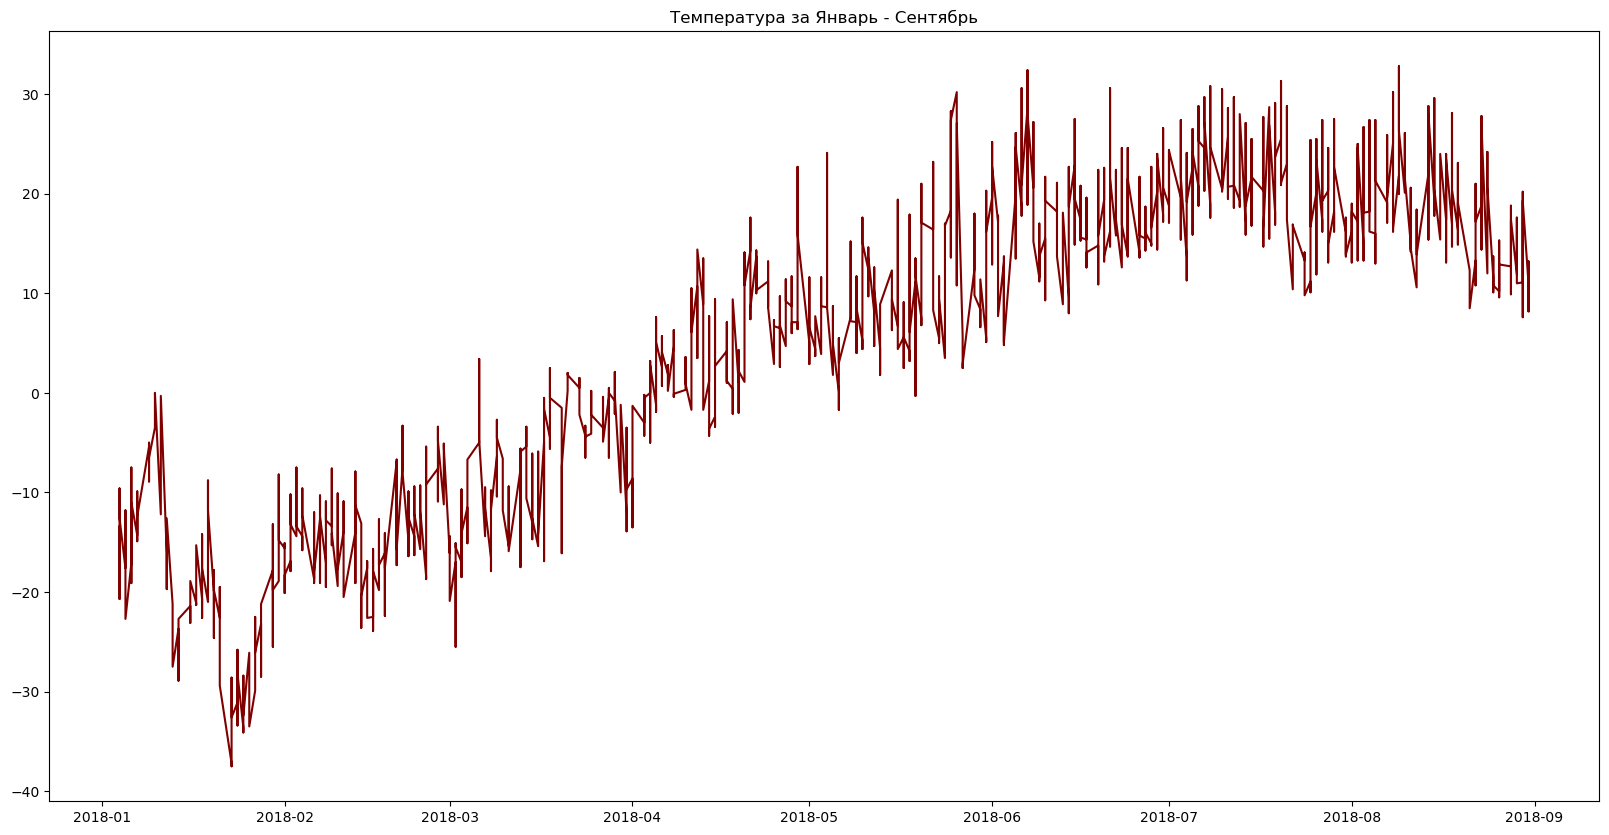

In [107]:
plt.figure(figsize=(20, 10))
plt.plot(grouped_df['Дата'],grouped_df['T'], color = 'maroon')
plt.title('Температура за Январь - Сентябрь')
plt.show()